# Demo 2 · Clustering jerárquico: ¿qué países se parecen?

**La pregunta de negocio.** Una fintech argentina quiere expandirse a otros países. Antes de analizar mercado por mercado, quiere saber **qué países se parecen entre sí** en nivel de desarrollo, para armar una estrategia por grupo de países (si funciona en uno, probablemente funcione en los parecidos).

Diferencias con K-means:
- **No hay que elegir K de antemano**: el algoritmo arma un árbol completo de uniones (el *dendrograma*) y después decidimos dónde cortarlo.
- Con pocos casos (decenas o cientos) el dendrograma es súper visual y fácil de explicar.

**Dataset:** indicadores de Naciones Unidas (~2010) para 193 países (paquete `carData` de R).
- `fertility`: hijos por mujer
- `ppgdp`: PBI per cápita (USD)
- `lifeExpF`: esperanza de vida de las mujeres
- `pctUrban`: % de población urbana
- `infantMortality`: muertes por cada 1000 nacidos vivos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
pd.set_option("display.precision", 2)
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [2]:
df = pd.read_csv("data/paises_onu.csv").rename(columns={"rownames": "pais"}).dropna()
df = df.set_index("pais")
print(df.shape)
df.head()

(193, 7)


,region,group,fertility,ppgdp,lifeExpF,pctUrban,infantMortality
pais,,,,,,,
Afghanistan,Asia,other,5.97,499.0,49.49,23.0,124.53
Albania,Europe,other,1.52,3677.2,80.40,53.0,16.56
Algeria,Africa,africa,2.14,4473.0,75.00,67.0,21.46
Angola,Africa,africa,5.13,4321.9,53.17,59.0,96.19
Argentina,Latin Amer,other,2.17,9162.1,79.89,93.0,12.34


## 1. Preparar los datos

- El PBI per cápita va de 100 a 100.000 USD: tiene una cola muy larga. Usamos el **logaritmo** para que unos pocos países ricos no dominen todo.
- Después **estandarizamos**, igual que en K-means: el jerárquico también trabaja con distancias.

In [3]:
variables = ["fertility", "ppgdp", "lifeExpF", "pctUrban", "infantMortality"]
X = df[variables].copy()
X["ppgdp"] = np.log10(X["ppgdp"])
X_esc = StandardScaler().fit_transform(X)

## 2. Empecemos chico: los países de América

El algoritmo:
1. Arranca con cada país como su propio grupo.
2. Junta los dos grupos más parecidos.
3. Repite hasta que queda un solo grupo.

Usamos el criterio **Ward**: en cada paso une los dos grupos que menos "desordenan" (aumentan la variabilidad interna). Suele dar grupos parecidos a los de K-means y es el más usado.

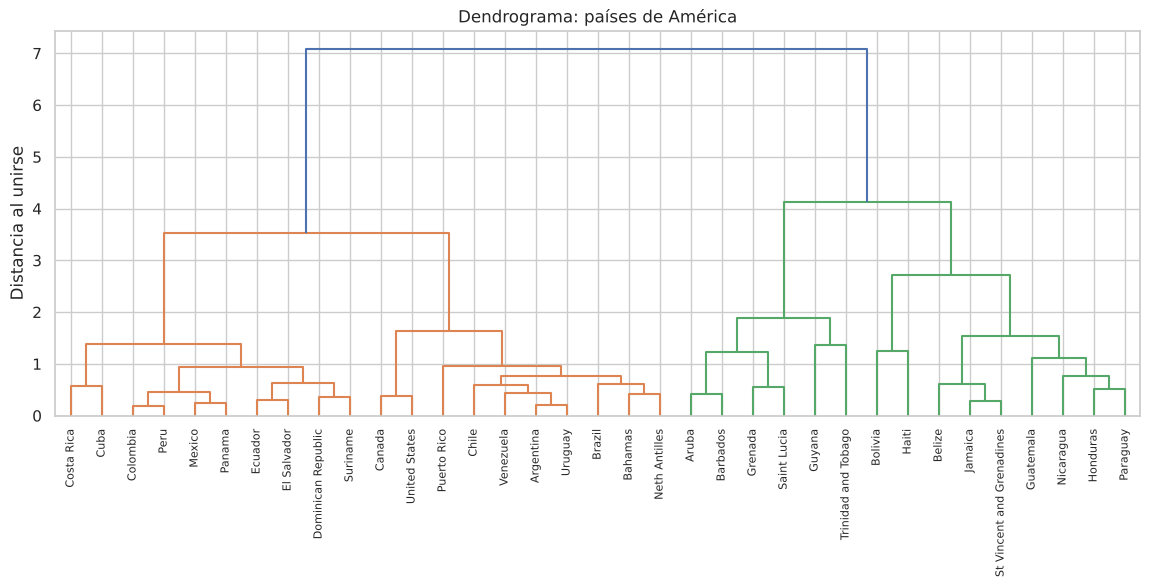

In [4]:
america = df.region.isin(["Latin Amer", "Caribbean", "North America"]).values
Z_am = linkage(X_esc[america], method="ward")

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z_am, labels=df.index[america].tolist(), leaf_rotation=90, ax=ax)
ax.set_ylabel("Distancia al unirse")
ax.set_title("Dendrograma: países de América");

### Cómo se lee

- Cada hoja de abajo es un país.
- Una "U" invertida une dos grupos. **La altura de la unión** = qué tan distintos eran cuando se juntaron.
- Uniones bajas: países muy parecidos (ej. Argentina y Uruguay). Uniones altas: grupos muy distintos.
- **Cortar** el árbol con una línea horizontal define los grupos. Buscamos cortar donde hay un "salto" grande de altura.

**Pregunta para la clase:** ¿con quién se junta Argentina primero? ¿Te sorprende?

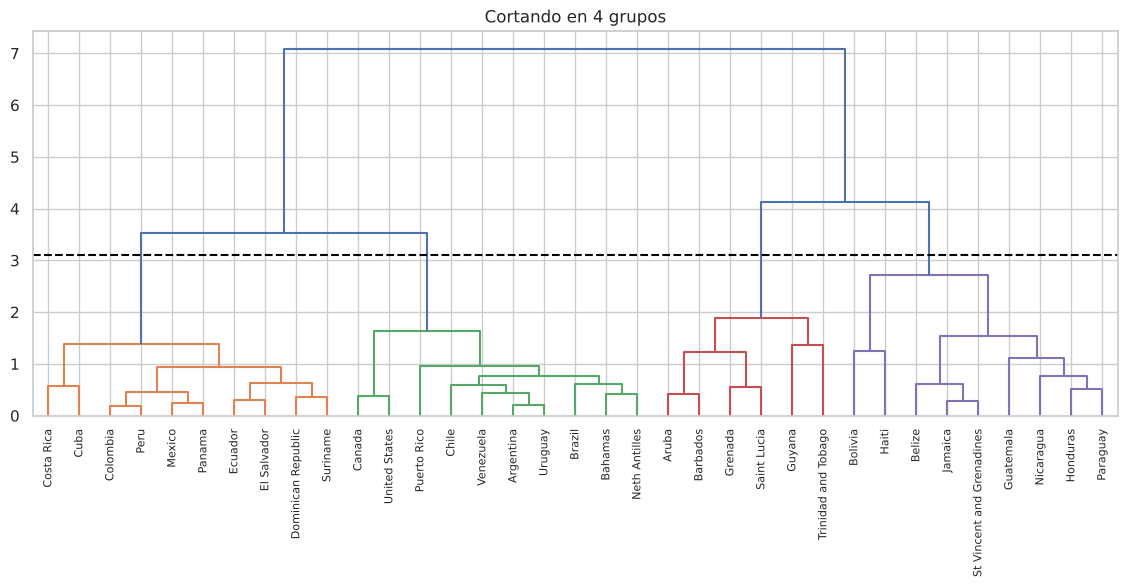

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z_am, labels=df.index[america].tolist(), leaf_rotation=90, ax=ax, color_threshold=3.1)
ax.axhline(3.1, color="black", ls="--")
ax.set_title("Cortando en 4 grupos");

## 3. Todos los países

Con 193 hojas el dendrograma completo no se lee, así que mostramos solo las últimas uniones (los números entre paréntesis son cuántos países hay en cada rama).

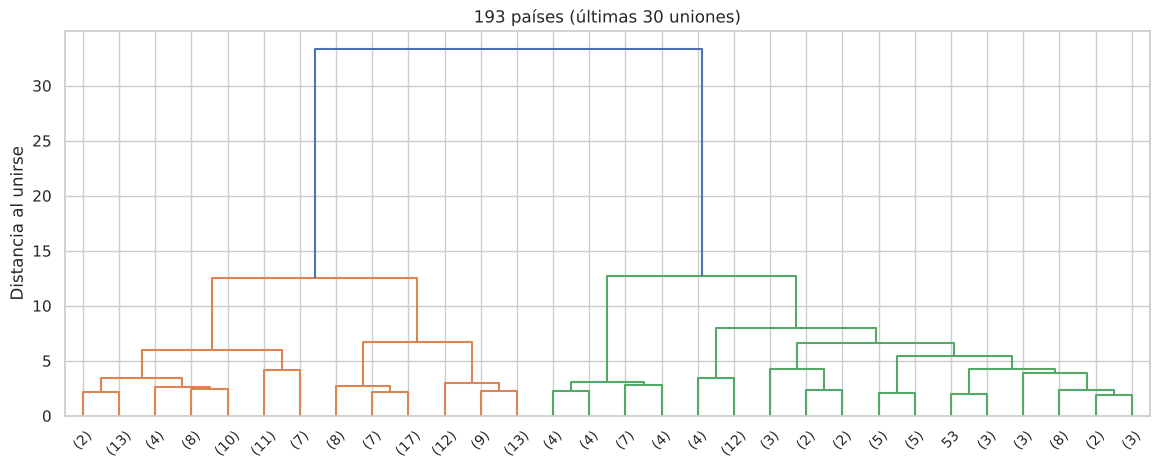

In [6]:
Z = linkage(X_esc, method="ward")

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, show_leaf_counts=True)
ax.set_ylabel("Distancia al unirse")
ax.set_title("193 países (últimas 30 uniones)");

In [7]:
# Probemos distintas cantidades de grupos: un corte del árbol = una K
for k in [2, 3, 4, 5, 6]:
    grupos = fcluster(Z, t=k, criterion="maxclust")
    print(f"{k} grupos → tamaños: {sorted(np.bincount(grupos)[1:].tolist(), reverse=True)}")

2 grupos → tamaños: [121, 72]
3 grupos → tamaños: [121, 53, 19]
4 grupos → tamaños: [66, 55, 53, 19]
5 grupos → tamaños: [66, 55, 37, 19, 16]
6 grupos → tamaños: [55, 37, 34, 32, 19, 16]


In [8]:
df["grupo"] = fcluster(Z, t=4, criterion="maxclust")
perfil = df.groupby("grupo")[variables].median()
perfil["paises"] = df.groupby("grupo").size()
perfil.sort_values("ppgdp")

,fertility,ppgdp,lifeExpF,pctUrban,infantMortality,paises
grupo,,,,,,
3,5.49,450.80,53.14,36.0,92.21,19
4,3.76,1239.80,64.41,36.0,47.49,53
1,2.03,4495.80,77.31,53.0,17.32,55
2,1.85,20556.05,80.65,80.5,6.48,66


Ponerle nombre a cada grupo, mirando las medianas:

In [9]:
orden = perfil.sort_values("ppgdp").index
nombres = dict(zip(orden, ["Bajo desarrollo", "Desarrollo medio-bajo", "Desarrollo medio-alto", "Alto desarrollo"]))
df["grupo_nombre"] = df.grupo.map(nombres)

for g in nombres.values():
    paises = df.index[df.grupo_nombre == g]
    print(f"{g} ({len(paises)}): {', '.join(paises[:15])}{'...' if len(paises) > 15 else ''}\n")

Bajo desarrollo (19): Afghanistan, Benin, Burkina Faso, Burundi, Central African Republic, Chad, Democratic Republic of the Congo, Guinea, Guinea-Bissau, Liberia, Malawi, Mali, Mozambique, Niger, Rwanda...

Desarrollo medio-bajo (53): Angola, Bangladesh, Bhutan, Bolivia, Botswana, Cambodia, Cameroon, Comoros, Congo, Cote dIvoire, Djibouti, Timor Leste, Equatorial Guinea, Eritrea, Ethiopia...

Desarrollo medio-alto (55): Albania, Algeria, Armenia, Aruba, Azerbaijan, Barbados, Belize, Bosnia and Herzegovina, Cape Verde, China, Croatia, Dominican Republic, Ecuador, Egypt, El Salvador...

Alto desarrollo (66): Argentina, Australia, Austria, Bahamas, Bahrain, Belarus, Belgium, Brazil, Brunei Darussalam, Bulgaria, Canada, Chile, Colombia, Cook Islands, Costa Rica...



In [10]:
print("Argentina está en:", df.loc["Argentina", "grupo_nombre"])
df[df.grupo_nombre == df.loc["Argentina", "grupo_nombre"]].query("region in ['Latin Amer', 'Caribbean', 'Europe']").index.tolist()

Argentina está en: Alto desarrollo


['Argentina',
 'Austria',
 'Bahamas',
 'Belarus',
 'Belgium',
 'Brazil',
 'Bulgaria',
 'Chile',
 'Colombia',
 'Costa Rica',
 'Cuba',
 'Czech Republic',
 'Denmark',
 'Estonia',
 'Finland',
 'France',
 'Germany',
 'Hungary',
 'Iceland',
 'Italy',
 'Latvia',
 'Lithuania',
 'Luxembourg',
 'Malta',
 'Mexico',
 'Neth Antilles',
 'Netherlands',
 'Norway',
 'Panama',
 'Peru',
 'Puerto Rico',
 'Russian Federation',
 'Spain',
 'Suriname',
 'Sweden',
 'Switzerland',
 'Ukraine',
 'United Kingdom',
 'Uruguay',
 'Venezuela']

## 4. ¿Importa el criterio de unión?

¿Cómo se mide la distancia entre dos **grupos** de países? Hay varias opciones:
- **single**: la distancia entre los dos países más cercanos de cada grupo. Tiende a formar "cadenas".
- **complete**: entre los dos más lejanos.
- **average**: el promedio de todas las distancias.
- **ward**: el que menos aumenta la variabilidad interna (el que usamos).

Mirá cómo cambia el dendrograma de América:

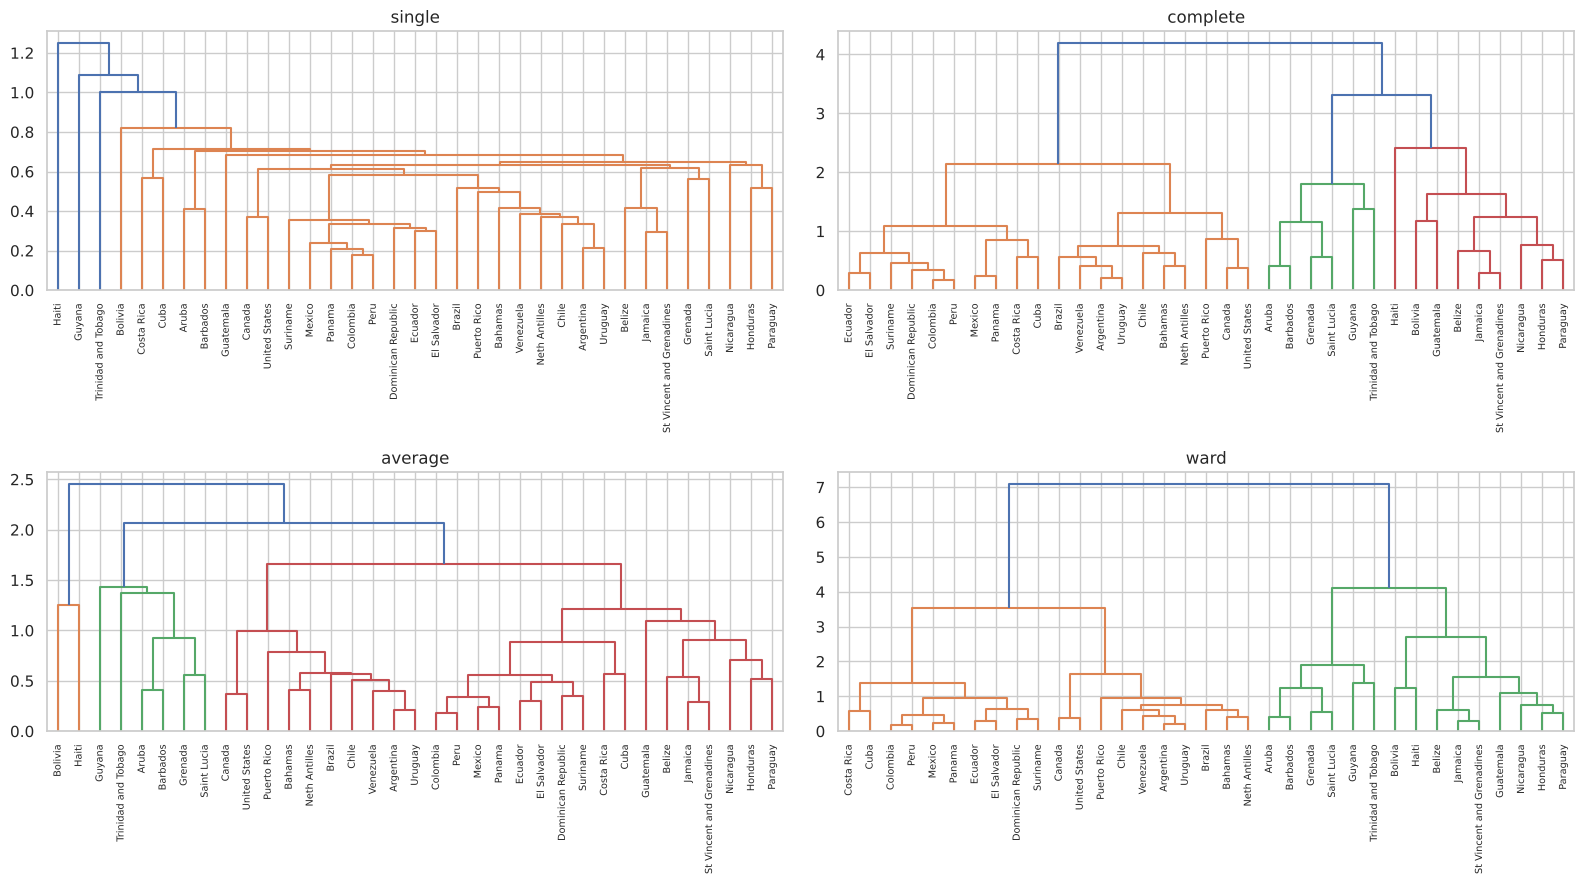

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, metodo in zip(axes.flat, ["single", "complete", "average", "ward"]):
    dendrogram(linkage(X_esc[america], method=metodo), labels=df.index[america].tolist(),
               leaf_rotation=90, leaf_font_size=7, ax=ax)
    ax.set_title(metodo)
plt.tight_layout()

Con **single** casi todos los países se van sumando de a uno a un grupo gigante: no sirve para segmentar. **Ward** da grupos más balanceados y fáciles de interpretar.

## 5. Para pensar en clase

1. Si la fintech solo puede atacar **un** grupo de países, ¿cuál elegirías y por qué? ¿Qué otras variables agregarías (bancarización, uso de celular, regulación...)?
2. ¿Qué pasa si **no** aplicamos el logaritmo al PBI? Probalo.
3. ¿Cuándo usarías jerárquico y cuándo K-means? (Pista: pensá en cuántas filas tenés y en si sabés el K.)